In [1]:
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
from utils import numtostr
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


raw_dir = Path("data/raw")
raw_dir.mkdir(parents = True, exist_ok = True)

zip_file = raw_dir / "online_retail.zip"
excel_file = raw_dir / "Online Retail.xlsx"

# 1. Download and extract if not already cached
if not excel_file.exists():
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    print("Downloading archive from UCI repository...")
    req = urllib.request.Request(url, headers = {"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(zip_file, "wb") as f:
        f.write(resp.read())
        
    print("Extracting workbook...")
    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall(raw_dir)
    print("Extraction complete.")

# 2. Ingest the uncompressed workbook
print("Loading Excel into DataFrame (takes ~15-25 seconds)...")
df_raw = pd.read_excel(excel_file, engine = "openpyxl")

print(f"Ingestion complete. Raw shape: {df_raw.shape}")
df_raw.head(5)

Extracting workbook...
Extraction complete.
Loading Excel into DataFrame (takes ~15-25 seconds)...
Ingestion complete. Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<br><br>
- Ghost Revenue Audit: Quantified the unauthenticated transaction leakage at £1,447,682.12, representing 14.85% of total gross sales. 

- Transactional Data Sanitation: Filtered out cancellations, negative volume entries, and non-merchandise service fee codes non_service_codes = ['POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'CR'].   

- Timeframe Standardization: Removed the partial final month (December 2011) to prevent time-truncation bias.   

- Temporal Cohort Coordinates: Established customer acquisition cohorts (CohortMonth), transaction periods (Invoice_Month), and relative lifecycle intervals (Index_Month).  

- Customer Retention Headcount Matrix: Built the cohort-by-month grid tracking the absolute number of active unique customers over time.   

- Percentage Retention Matrix: Calculated the baseline retention rates normalized to Month 0 cohort sizes.   

- Month-1 Churn Benchmark: Determined the baseline Month-1 average retention across cohorts (21.27%, reflecting a 78.73% drop-off cliff).   

- Cohort Net Revenue Matrix: Aggregated the monthly monetary sales generated by each acquisition cohort.   

- Cumulative Revenue Matrix: Tracked the running cash volume accumulated by each cohort over its lifecycle.   

- Cumulative LTV Matrix (ARPU): Derived the historical lifetime value curve showing the average cumulative dollars generated per acquired user. 

- Pareto Revenue Concentration: Identified top customer spending inequality, confirming that the top 20% of buyers generate 73.97% of total company sales.   

- Inter-Purchase Latency Distribution: Measured repeat order timing between Order 1 and Order 2, isolating the mean (75.8 days), median (50 days), and 75th percentile threshold (111.8 days). 

In [2]:
# Calculating Gross Revenue From The Existing Data. 
df_raw["GrossRevenue"] = (df_raw["UnitPrice"] * df_raw["Quantity"]).round(2)
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
# So Here We Have NaN In Two Columns (Description), (CustomerID) In This Data_Frame,
df_raw.isna().sum()

InvoiceNo            0
StockCode            0
Description       1454
Quantity             0
InvoiceDate          0
UnitPrice            0
CustomerID      135080
Country              0
GrossRevenue         0
dtype: int64

In [4]:
# Since We Are Going To Do Analysis Based On Our Acquired Customers, So We Cannot Just Fill Anything Over Those Missing Customer_Id's,
# We Are Going To Seprate Those Anonymous/Unknown Customers Data.
ghost_df = df_raw[(df_raw["CustomerID"].isna())].copy()
ghost_df.head(5)
# We Got (135080) Transactions Where Customer-IDs Are Not Mentioned.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom,0.00
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom,2.51
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom,3.40
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom,3.32


In [5]:
# Calculating The Net Revenue, Coming From These Anonymous Transactions.
unattributed_gross_revenue = ghost_df["GrossRevenue"].sum()
print(unattributed_gross_revenue)
# So We Got (1447682.12) This Amount Of Net Revenue Coming From Those Anonymous Transactions.

1447682.12


In [6]:
total_gorss_revenue = df_raw["GrossRevenue"].sum()

In [7]:
# Lets See How Much This Contributes To The Total Companies Gross Revenue.
print(f"Total Companies Gross Revenue : {total_gorss_revenue}")
anonymous_prctg = ((unattributed_gross_revenue / total_gorss_revenue) * 100).round(2)
print(f"The Exact Metric Measuring How Much Money Is Generated By These Anonymous Transactions Is : {anonymous_prctg}%")

Total Companies Gross Revenue : 9747747.93
The Exact Metric Measuring How Much Money Is Generated By These Anonymous Transactions Is : 14.85%


In [8]:
tracked_gross_revenue = (df_raw.loc[~(df_raw["CustomerID"].isna()), "GrossRevenue"]).sum()

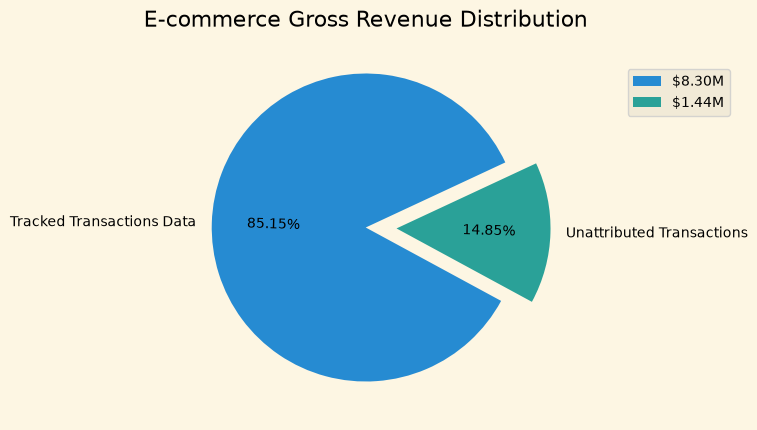

In [9]:
# plotting the gross revenue data in the chart to see the distribution.
revenues = [tracked_gross_revenue, unattributed_gross_revenue]

plt.style.use('Solarize_Light2')
fig, ax = plt.subplots(figsize = (15,5))
pie_plot = ax.pie(revenues, explode = [0, 0.2], labels = ["Tracked Transactions Data", "Unattributed Transactions"], startangle = +25)
plt.title("E-commerce Gross Revenue Distribution")
ax.pie_label(pie_plot, '{frac:.2%}', rotate = True)
ax.legend(numtostr(tracked_gross_revenue, unattributed_gross_revenue), loc = (1.18,0.79), fontsize = "medium")
plt.show()

In [10]:
# Now We Can Safely Remove Those Unknown Customers Data From Our Working Data_Frame.
df_raw = df_raw.dropna(subset = "CustomerID")

In [11]:
# Impute missing product descriptions with 'Unknown-Item' to preserve transaction records
# and keep unlabelled entries trackable during product-level aggregations.
df_raw["Description"] = df_raw["Description"].fillna("Unknown-Item")

In [12]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     406829 non-null  object        
 1   StockCode     406829 non-null  object        
 2   Description   406829 non-null  object        
 3   Quantity      406829 non-null  int64         
 4   InvoiceDate   406829 non-null  datetime64[us]
 5   UnitPrice     406829 non-null  float64       
 6   CustomerID    406829 non-null  float64       
 7   Country       406829 non-null  str           
 8   GrossRevenue  406829 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 36.2+ MB


<br><br>
### Important Explanation:
Since We Got Multiple Data Type Like Int/Str In This InvoiceNo Column, Pandas Convert This To An Object, Rather Than An Specific Type (Str/Int), <br>
And When We Try To Run An String Method With Str Accessor (df_raw.str.lower()), <br>
You May Think That Those Integer Values Will Be Converted Down To An String Value Like (Eg, "12346"), <br>
But Rather Than Doing That Pandas Simply Returns NaN For Those Integer Places, This Can Silently Break Your Code Logics, Even Though You May Think It Is Correct. <br>
So To Avoid This Behaviour We Explicitely Converted This Coulms Data Type To String, Those Integers Will Be Converted To Strings Like (Eg, "12346") <br>

In [13]:
# Managing The Data Type For These Columns (Quantity, UnitPrice, CustomerID, Description) To Save Up Ram Usage.
df_raw["Quantity"] = df_raw["Quantity"].astype("int32")
df_raw["UnitPrice"] = df_raw["UnitPrice"].astype("float32")
df_raw["CustomerID"] = df_raw["CustomerID"].astype("float32")
df_raw["Description"] = df_raw["Description"].astype("str") 
df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype("str") 

In [14]:
# Filtering Out Non-Merchandise Service Fee Codes From The Data.

# Here Are The List Of Those StockCodes That We Have To Filter Out From Our Data. 
non_service_codes = ['POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'CR']
# First We Are Saving Those Non Service Tracnsactions Data.
non_service_transactions = df_raw[(df_raw["StockCode"].isin(non_service_codes))]
non_service_transactions.head(5)
# We Got (1754) Transactions Where StockCodes Are From Non Servicable Codes List.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583.0,France,54.00
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791.0,Netherlands,15.00
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662.0,Germany,18.00
2239,536569,M,Manual,1,2010-12-01 15:35:00,1.25,16274.0,United Kingdom,1.25


In [15]:
# Now We Have To Check What Are The Appearance Percentage Of Each Of These Codes In Our Working Data_Frame.
codes_count = non_service_transactions["StockCode"].value_counts()
codes_prctg = (codes_count / df_raw["StockCode"].count()) * 100
codes_prctg

StockCode
POST            0.293981
M               0.114299
D               0.018927
BANK CHARGES    0.002950
PADS            0.000983
Name: count, dtype: float64

In [16]:
# Now That We Have Analyzes What We Have To, From The Non Service Stock Codes Data, We Can Now Safely Remove Those from Our Working Data Frame.
df_raw = df_raw[(~ (df_raw["StockCode"].isin(non_service_codes)))]

In [17]:
# Cancellation & Reversal Filtering, Excluding The Order InvoiceNo Entries That Starts With The Cancellation Indicator (C),
# As Well As Negative And Zero Quantity Entries To Isolate Genuine Completed Sales Order.
df_raw = df_raw[(~ (df_raw["Quantity"] <= 0)) & (~ (df_raw["InvoiceNo"].str.startswith("C")))]

In [18]:
# Note: December 2011 Contains Incomplete Records.
# We Are Excluding It To Ensure Our Analysis Relies Only On Full-Month Data (Ending November 2011).
df_raw = df_raw[(df_raw["InvoiceDate"] < "2011-12")]
df_raw.tail(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
516364,579885,85034C,3 ROSE MORRIS BOXED CANDLES,4,2011-11-30 17:37:00,1.25,15444.0,United Kingdom,5.00
516365,579885,21742,LARGE ROUND WICKER PLATTER,2,2011-11-30 17:37:00,5.95,15444.0,United Kingdom,11.90
516366,579885,23084,RABBIT NIGHT LIGHT,6,2011-11-30 17:37:00,2.08,15444.0,United Kingdom,12.48
516367,579885,21257,VICTORIAN SEWING BOX MEDIUM,1,2011-11-30 17:37:00,7.95,15444.0,United Kingdom,7.95
516368,579885,21259,VICTORIAN SEWING BOX SMALL,1,2011-11-30 17:37:00,5.95,15444.0,United Kingdom,5.95


In [19]:
# Now So That Our Data Frame Is Fully Cleaned, And Ready For The Analysict, We Can Drop Our df_raw Data_Frame.
df = df_raw
# Decremented The Reference Counter Of Our Raw Data Frame, This Should Eventually Remove The Entire Data Frame From The RAM. 
del df_raw

<br><br>
### Starting From Now We Will Analyze Our Data To Compute The Result That Will Be Helpfull In Answering Important Business Questions.

In [20]:
# Now Isolating The (Year-Month) From The InvoiceDate, As InvoiceMonth, This Is Solely For The Analysis Purpose.
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [21]:
# Finding The Acquisition Month Of Our Customer's.
AcquisitionMonth = df.groupby("CustomerID")[["InvoiceDate"]].min().reset_index()
AcquisitionMonth["InvoiceDate"] = AcquisitionMonth["InvoiceDate"].dt.to_period("M")
AcquisitionMonth = AcquisitionMonth.rename(columns = {"InvoiceDate" : "CohortMonth"})
# The December 2010 Cohort Acquired The Largest Volume Of New Customers, 
# Accounting For 884 Distinct Customer Made Thier First Transactions.

Acquisition_Month_Distribution = AcquisitionMonth["CohortMonth"].value_counts()
print(f"Here Is How Many New Customers We Gain In Each Cohort Month : \n{Acquisition_Month_Distribution}")
# Display The Cohort Sizes As Percentages Of The Total Customer Base
Acquisition_Month_Percentage_Distribution = (AcquisitionMonth["CohortMonth"].value_counts(normalize = True) * 100).round(2)
print(f"\nHere Is The Percentage Distribution For Each Cohort Month : \n{Acquisition_Month_Percentage_Distribution}")

Here Is How Many New Customers We Gain In Each Cohort Month : 
CohortMonth
2010-12    884
2011-03    452
2011-01    416
2011-02    380
2011-10    357
2011-11    324
2011-04    300
2011-09    299
2011-05    284
2011-06    242
2011-07    187
2011-08    169
Freq: M, Name: count, dtype: int64

Here Is The Percentage Distribution For Each Cohort Month : 
CohortMonth
2010-12    20.59
2011-03    10.53
2011-01     9.69
2011-02     8.85
2011-10     8.31
2011-11     7.55
2011-04     6.99
2011-09     6.96
2011-05     6.61
2011-06     5.64
2011-07     4.35
2011-08     3.94
Freq: M, Name: proportion, dtype: float64


In [22]:
# Formatting (Years) So That We Can Easily Distnguish Where We Started Our First Month Of This Year (Jan).
# Formatting This As (Dec-11, Jan-10) Like This. 
Acquisition_Month_Distribution = (Acquisition_Month_Distribution.reset_index()).sort_values(by = "CohortMonth")
Acquisition_Month_Distribution["CohortMonth"] = Acquisition_Month_Distribution["CohortMonth"].dt.strftime("%b-%y")
Acquisition_Month_Distribution

,CohortMonth,count
0,Dec-10,884
2,Jan-11,416
3,Feb-11,380
1,Mar-11,452
6,Apr-11,300
8,May-11,284
9,Jun-11,242
10,Jul-11,187
11,Aug-11,169
7,Sep-11,299


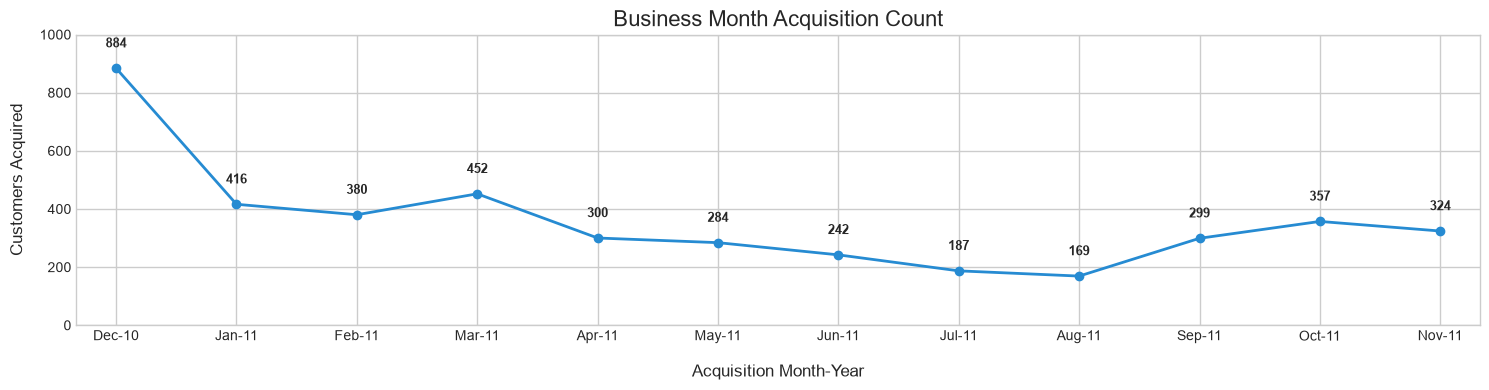

In [23]:
# here is the customer acquisition count for all the valid complete months from the data. 
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize = (15,4))
ax.plot(Acquisition_Month_Distribution["CohortMonth"], Acquisition_Month_Distribution["count"], marker = "o")
plt.grid(True)
ax.set(title = "Business Month Acquisition Count")
ax.set_ylabel("Customers Acquired", labelpad = 10)
ax.set_xlabel("Acquisition Month-Year", labelpad = 15)
ax.set_ylim(0, 1000)
ax.margins(x = 0.03)
plt.tight_layout()

for x, y in zip(Acquisition_Month_Distribution["CohortMonth"], Acquisition_Month_Distribution["count"]):
    ax.annotate(f"{y}", xy = (x, y), xytext = (0, 15), ha = "center", textcoords = "offset points", fontsize = 9, fontweight = "bold")

<br><br>
## Customer Acquisition Trend:
Customer acquisition peaks at 884 in Dec-10 (where we have acquired our top-buyers (B2B) with a large count, in that period),
Which continues till the end of the Q1 of the (2010 Jan to Mar),
and again we have that window coming up, where we have to again pivot our marketing strategies to acquire those (B2B) customers,
so we have to analyze our previous strategy that we uses previous year, to bring those heavy spenders,
so we can capture them in this upcoming window as well,
while also doing a heavy marketing for the whole sales buyers,
so that we can capture new (B2B) buyers, while giving a favour to our existing (B2B) customers,
Cause they came in majority in this window (Sep to Dec) and make heavy purchases,

In [24]:
df = pd.merge(df, AcquisitionMonth, on = "CustomerID", how = "left")
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue,InvoiceMonth,CohortMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12


In [25]:
Active_Customers_Transactions = df.groupby(["CustomerID", "InvoiceMonth"])[["CohortMonth"]].min().reset_index()
Active_Customers_Transactions["Index_Month"] = Active_Customers_Transactions["InvoiceMonth"].astype(int) - Active_Customers_Transactions["CohortMonth"].astype(int)
Active_Customers_Transactions.head(5)

,CustomerID,InvoiceMonth,CohortMonth,Index_Month
0,12346.0,2011-01,2011-01,0
1,12347.0,2010-12,2010-12,0
2,12347.0,2011-01,2010-12,1
3,12347.0,2011-04,2010-12,4
4,12347.0,2011-06,2010-12,6


In [26]:
df = pd.merge(df, Active_Customers_Transactions, on = ["CustomerID", "InvoiceMonth", "CohortMonth"], how = "left")
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue,InvoiceMonth,CohortMonth,Index_Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0


In [27]:
# Customer Retention Headcount Matrix: Built the cohort-by-month grid tracking the absolute number of active unique customers over time.   
Retention_HeadCount = df.groupby(["CohortMonth", "Index_Month"])[["CustomerID"]].nunique().unstack().droplevel(axis = 1, level = 0)
Retention_HeadCount

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,884.0,323.0,286.0,339.0,320.0,352.0,320.0,308.0,312.0,349.0,330.0,444.0
2011-01,416.0,91.0,111.0,95.0,132.0,120.0,103.0,100.0,123.0,136.0,152.0,NaN
2011-02,380.0,71.0,71.0,109.0,103.0,93.0,97.0,104.0,94.0,116.0,NaN,NaN
2011-03,452.0,67.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,NaN,NaN,NaN
2011-04,300.0,63.0,61.0,63.0,59.0,68.0,65.0,78.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,80.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,187.0,33.0,38.0,42.0,51.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,34.0,41.0,41.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
Cohorts_Aquisition = Retention_HeadCount[0]
Retention_In_Percentage = (Retention_HeadCount.div(Cohorts_Aquisition, axis = 0) * 100).round(2)
Retention_In_Percentage

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,100.0,36.54,32.35,38.35,36.20,39.82,36.20,34.84,35.29,39.48,37.33,50.23
2011-01,100.0,21.88,26.68,22.84,31.73,28.85,24.76,24.04,29.57,32.69,36.54,NaN
2011-02,100.0,18.68,18.68,28.68,27.11,24.47,25.53,27.37,24.74,30.53,NaN,NaN
2011-03,100.0,14.82,25.22,19.91,22.35,16.81,26.77,23.01,27.88,NaN,NaN,NaN
2011-04,100.0,21.00,20.33,21.00,19.67,22.67,21.67,26.00,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.06,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,17.65,20.32,22.46,27.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.12,24.26,24.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


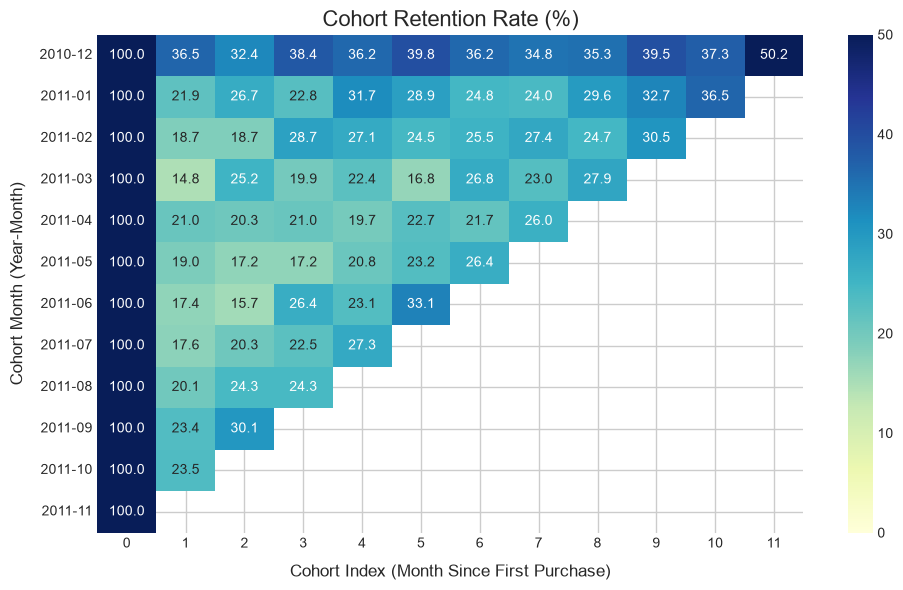

In [29]:
plt.figure(figsize=(10, 6))
sns.heatmap(Retention_In_Percentage, annot = True, fmt = ".1f", vmin = 0.0, vmax = 50.0, cmap = "YlGnBu")
plt.title("Cohort Retention Rate (%)")
plt.ylabel("Cohort Month (Year-Month)", labelpad = 10)
plt.xlabel("Cohort Index (Month Since First Purchase)", labelpad = 10)
plt.tight_layout()
plt.show()

<br><br>
- ### Observation: 
Across the Q1 to Q3 cohorts of 2011, we see a severe retention decline in Month 1, 
dropping into the (14.8% to 23.4%) range. However, if a customer survives past Month 2, 
their retention stabilizes into a consistent baseline.

- ### Implication:
We are successfully acquiring customers through marketing but failing to transition them into repeat buyers,
The first 30 days are the critical failure point.

- ### Possible Next Step: 
Implement an retention campaign. 
If we trigger vouchers, discounts, or re-engagement emails before the 30-day mark,
we can bridge this drop-off. Once they make that second purchase,
the data shows they are highly likely to remain in our active customer base.

<br>

- ### Observation:
Customers acquired in the later months of the year (Sept–Dec) display a distinct pattern,
Their initial Month-1 retention is noticeably higher.
Furthermore, the December 2010 cohort showed incredible long-term loyalty,
peaking at a massive 50.2% retention in Month 11 (November 2011).

- ### Implication:
This suggests that Q4 acquisitions are likely annual holiday or wholesale shoppers returning for the next season.

- ### Data Limitation & Possible Next Step: 
Because we only have a single month of historical Q4 data (Dec 2010), 
we must be careful not to over-extrapolate. Before shifting our entire budget to Q4, 
we need to query whether that December 2010 cohort was influenced by a unique external event,
(e.g., a new branch opening or a major category launch).

In [30]:
Business_Month_Gross_Revenue = ((df.groupby("InvoiceMonth")[["GrossRevenue"]].sum()).reset_index()).sort_values(by = "InvoiceMonth")
Business_Month_Gross_Revenue = Business_Month_Gross_Revenue.rename(columns = {"InvoiceMonth" : "MonthlyPeriod"})
Business_Month_Gross_Revenue["SalesMonthYear"] = Business_Month_Gross_Revenue["MonthlyPeriod"].dt.strftime("%b-%y")
Business_Month_Gross_Revenue["FormattedLabels"] = numtostr(*(tuple(Business_Month_Gross_Revenue["GrossRevenue"])))
Business_Month_Gross_Revenue

,MonthlyPeriod,GrossRevenue,SalesMonthYear,FormattedLabels
0,2010-12,568040.72,Dec-10,$568.04K
1,2011-01,564226.64,Jan-11,$564.22K
2,2011-02,443546.02,Feb-11,$443.54K
3,2011-03,585262.85,Mar-11,$585.26K
4,2011-04,455666.91,Apr-11,$455.66K
5,2011-05,660917.90,May-11,$660.91K
6,2011-06,654932.56,Jun-11,$654.93K
7,2011-07,593231.90,Jul-11,$593.23K
8,2011-08,637168.41,Aug-11,$637.16K
9,2011-09,943482.64,Sep-11,$943.48K


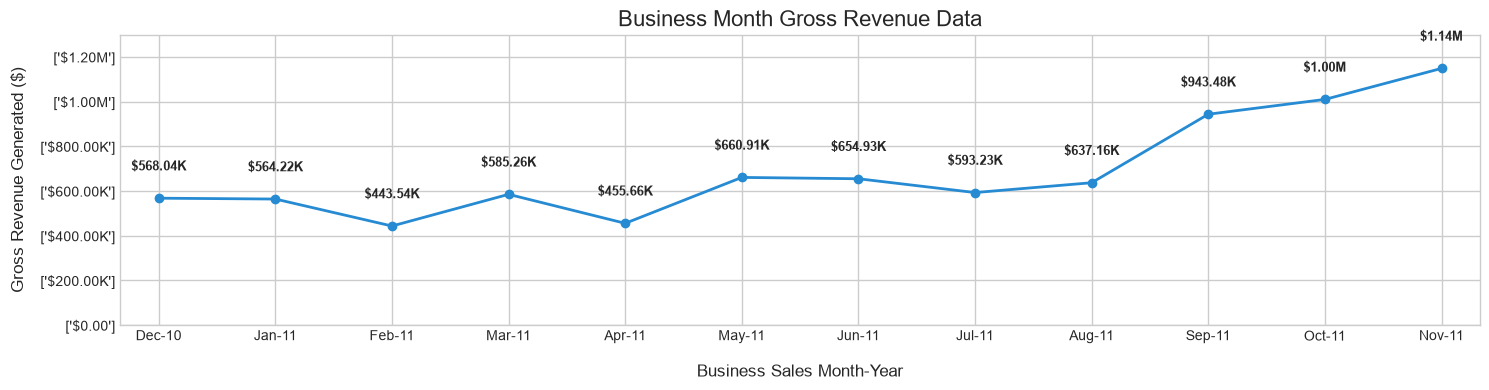

In [31]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize = (15,4))
ax.plot(Business_Month_Gross_Revenue["SalesMonthYear"], Business_Month_Gross_Revenue["GrossRevenue"], marker = "o")
plt.grid(True)
ax.set(title = "Business Month Gross Revenue Data")
ax.set_ylabel("Gross Revenue Generated ($)", labelpad = 10)
ax.set_xlabel("Business Sales Month-Year", labelpad = 15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos: numtostr(val)))
ax.set_ylim(0 , 1_300_000)

ax.margins(x = 0.03)
plt.tight_layout()

for x, y, label in zip(Business_Month_Gross_Revenue["SalesMonthYear"], Business_Month_Gross_Revenue["GrossRevenue"], Business_Month_Gross_Revenue["FormattedLabels"]):
    ax.annotate(
        label,                        
        xy=(x, y),                    
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

<br><br>
### Observation:
we have grown our gross sales from **($568.24k -> $1.14M)** in just 11 Month Of Time-Line,
so it suggest that our previous business strategy seems to be working, we have closed almost double in the amount of actuall sales,
compared to last years closing sales numbers

### Suggestion:
We should have to analyze what is the key reason that our sales get hiked even before the start of (Nov-Dec) month,

### Implication:
it sarted in September where we have seen an sales growth of ($306.66K) from the last month,
which is a huge jump if we compare it to this year entire month by month sales changes, 
So this change seems to take place before the (Nov-Dec) month,
which is the month where seasonal customers satrted to show up,
so this suggest that these are rather an whole sale buyers (B2B) customers,
who buys in bulk, 

### Business Strategy & Possible Next Step:
this insight suggests that marketing and supply chain timelines must be shifted backward,
If our biggest buyers are placing million-dollar orders in September,
our holiday marketing campaigns and bulk-discount pitches need to launch in July or August, not on October,
and we should notify our inventory manager/head about this demand hike,
casue that gross sales number (Nov-11 $1.14M), the sales will not likely drop back down to the old $500k baseline in next coming year (2012),
so we should be prepared to full-fill those demands.

In [32]:
Aquired_Customers_Lifetime_Revenue = df.groupby(["CohortMonth", "Index_Month"])[["GrossRevenue"]].sum().unstack().droplevel(axis = 1, level = 0)
Aquired_Customers_Lifetime_Revenue
# Cohort Net Revenue Matrix: A Matrix Displaying The Total Monthly Sales Revenue Generated By Distinct Customer Cohorts Over Their Lifecycle.

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,568040.72,274352.84,232519.78,297653.57,202661.01,326617.15,311859.78,308346.52,327484.75,471054.61,449964.29,509209.39
2011-01,289873.80,53284.71,62573.22,64954.61,80049.89,83328.88,69582.40,71542.44,71540.86,104852.41,122267.06,NaN
2011-02,157741.53,27668.94,39055.57,48102.41,39974.91,33913.33,49603.83,60607.68,55146.33,64278.45,NaN,NaN
2011-03,197367.12,28737.13,58520.80,42444.22,50509.65,39834.81,64626.69,68781.88,70864.04,NaN,NaN,NaN
2011-04,120258.59,28649.27,24799.39,24133.47,26152.19,29523.50,28365.65,33940.61,NaN,NaN,NaN,NaN
2011-05,118978.38,18534.20,20003.64,19010.17,27703.79,32443.10,33007.91,NaN,NaN,NaN,NaN,NaN
2011-06,133991.18,14144.76,13369.40,30258.80,26237.20,40305.93,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,72598.13,11537.67,15044.20,17374.47,18992.37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,78633.15,20842.93,35114.40,44178.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
# Aggregating All-Time Cumulative Revenue Generated By Each Cohort Group.
# Note: Older Cohorts Will Naturally Skew Higher As They Have Had More Months To Accumulate Spend.
Revenue_Generated_By_Cohort = Aquired_Customers_Lifetime_Revenue.sum(axis = 1).reset_index().rename(columns = {0 : "TotalRevenue"})
Revenue_Generated_By_Cohort

,CohortMonth,TotalRevenue
0,2010-12,4279764.41
1,2011-01,1073850.28
2,2011-02,576092.98
3,2011-03,621686.34
4,2011-04,315822.67
5,2011-05,269681.19
6,2011-06,258307.27
7,2011-07,135546.84
8,2011-08,178768.99
9,2011-09,216814.58


In [34]:
Aquired_Customers_Cumulative_Revenue = Aquired_Customers_Lifetime_Revenue.cumsum(axis = 1)
Aquired_Customers_Cumulative_Revenue

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,568040.72,842393.56,1074913.34,1372566.91,1575227.92,1901845.07,2213704.85,2522051.37,2849536.12,3320590.73,3770555.02,4279764.41
2011-01,289873.80,343158.51,405731.73,470686.34,550736.23,634065.11,703647.51,775189.95,846730.81,951583.22,1073850.28,NaN
2011-02,157741.53,185410.47,224466.04,272568.45,312543.36,346456.69,396060.52,456668.20,511814.53,576092.98,NaN,NaN
2011-03,197367.12,226104.25,284625.05,327069.27,377578.92,417413.73,482040.42,550822.30,621686.34,NaN,NaN,NaN
2011-04,120258.59,148907.86,173707.25,197840.72,223992.91,253516.41,281882.06,315822.67,NaN,NaN,NaN,NaN
2011-05,118978.38,137512.58,157516.22,176526.39,204230.18,236673.28,269681.19,NaN,NaN,NaN,NaN,NaN
2011-06,133991.18,148135.94,161505.34,191764.14,218001.34,258307.27,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,72598.13,84135.80,99180.00,116554.47,135546.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,78633.15,99476.08,134590.48,178768.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# Cohort Lifetime Value (LTV) Growth: Tracks How The Average Value Of A Customer Scales Over Their Lifecycle,
# Allowing Us To See Exactly When A Cohort Breaks Even On Acquisition Costs.
Customer_LTV = Aquired_Customers_Cumulative_Revenue.div(Cohorts_Aquisition, axis = 0).round(2)
Customer_LTV

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,642.58,952.93,1215.97,1552.68,1781.93,2151.41,2504.19,2853.00,3223.46,3756.32,4265.33,4841.36
2011-01,696.81,824.90,975.32,1131.46,1323.89,1524.19,1691.46,1863.44,2035.41,2287.46,2581.37,NaN
2011-02,415.11,487.92,590.70,717.29,822.48,911.73,1042.26,1201.76,1346.88,1516.03,NaN,NaN
2011-03,436.65,500.23,629.70,723.60,835.35,923.48,1066.46,1218.63,1375.41,NaN,NaN,NaN
2011-04,400.86,496.36,579.02,659.47,746.64,845.05,939.61,1052.74,NaN,NaN,NaN,NaN
2011-05,418.94,484.20,554.63,621.57,719.12,833.36,949.58,NaN,NaN,NaN,NaN,NaN
2011-06,553.68,612.13,667.38,792.41,900.83,1067.39,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,388.23,449.92,530.37,623.29,724.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,465.28,588.62,796.39,1057.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
Earning_From_Each_Customers = df.groupby("CustomerID")[["GrossRevenue"]].sum().reset_index().rename(columns = {"GrossRevenue" : "CustomerValue"})
Earning_From_Each_Customers.head()

,CustomerID,CustomerValue
0,12346.0,77183.60
1,12347.0,4085.18
2,12348.0,1437.24
3,12349.0,1457.55
4,12350.0,294.40


In [37]:
# This Should Get Me The Count Of 20% Of Our Customer Base. 
Top_20_Percent_Headcount  = (Earning_From_Each_Customers["CustomerID"].count() * 0.20).round().astype("int")
print(f"20% Customer HeadCount : {Top_20_Percent_Headcount}")

20% Customer HeadCount : 859


In [38]:
# Extract the top 20% highest-value Customers Based On Their Historical Lifetime Spend.
# This Subset Represents Our Most Valuable Buyer Tier For Premium Revenue Analysis.
Top_Tier_CustomersID = Earning_From_Each_Customers.sort_values(by = "CustomerValue", ascending = False).head(Top_20_Percent_Headcount)
top_20_prct_buyers_id = list(Top_Tier_CustomersID["CustomerID"])
Top_Tier_CustomersID.head(10)

,CustomerID,CustomerValue
1672,14646.0,267410.00
4158,18102.0,248171.76
3690,17450.0,192988.39
1861,14911.0,133471.80
54,12415.0,124564.53
1320,14156.0,117379.63
3733,17511.0,83683.06
0,12346.0,77183.60
2672,16029.0,72882.09
985,13694.0,61908.46


In [39]:
sales_data_of_Remaining_80_prct = df.loc[(~(df["CustomerID"].isin(top_20_prct_buyers_id))), "GrossRevenue"].sum()
sales_data_of_top_20_prct = Top_Tier_CustomersID["CustomerValue"].sum()
revenue_distribution = [sales_data_of_Remaining_80_prct, sales_data_of_top_20_prct]
revenue_distribution

[np.float64(2149648.01), np.float64(6115031.31)]

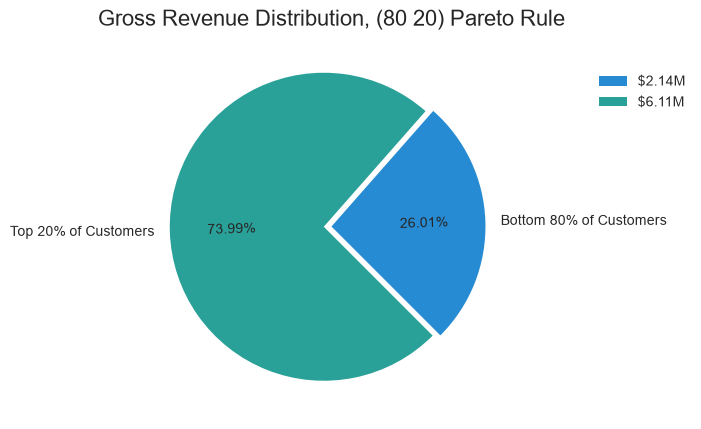

In [40]:
fig, ax = plt.subplots(figsize = (15,5))
pie_plot = ax.pie(revenue_distribution, explode = (0,0.05), labels = ["Bottom 80% of Customers", "Top 20% of Customers"], startangle = -45)
ax.set_title("Gross Revenue Distribution, (80 20) Pareto Rule")
ax.pie_label(pie_plot, '{frac:.2%}', rotate = True)
ax.legend(numtostr(revenue_distribution[0], revenue_distribution[1]), loc = (1.18,0.79), fontsize = "medium")

<br><br>
### Observation:
There is a pareto (80 20) distribution in our chart, even though we have (74 26),
where 74% of entire business gross sales comes from top-20% buyers,

### Implication:
so loosing just one customer from that top-20 group
will hurt the business 3 times more than losing customers from that bottom-80%

### Possible Next step:
So we should give an special treatment to those customers,
something like a gift or special treatment specially for VIP members,
that reduces the likely hood of loosing those customers.

In [41]:
len(top_20_prct_buyers_id)

859

In [42]:
# (Sep, Oct, Nov)
B2B_Buyers_Id = (df.loc[(df["InvoiceMonth"] > "2010-8") & (df["Index_Month"] > 0) & (df["GrossRevenue"] > 20.0) & (df["Quantity"] > 12), "CustomerID"])
B2B_Buyers_Id = B2B_Buyers_Id.drop_duplicates()
top_20_guarenteed = B2B_Buyers_Id[B2B_Buyers_Id.isin(top_20_prct_buyers_id)]
len(top_20_guarenteed)
# So we have confirmed that most of our VIP buyers happen to be (B2B) cusomers,
# who show up in these months (Sep, Oct, Nov) to place their big orders.

808

In [43]:
# Extract Unique Profile Data For Top-Tier Customers And Append Their Total Lifetime Value.
# The Resulting DataFrame Is Sorted In Descending Order To Prioritize Our Highest-Value VIP Accounts.
# Note: This Is An Optional Diagnostic Step To Inspect The Complete Operational Profiles Of Our Top Buyers.
Top_Tier_Customers_info = df[(df["CustomerID"].isin(Top_Tier_CustomersID["CustomerID"]))].drop_duplicates(subset = "CustomerID")
Top_Tier_Customers_info = pd.merge(Top_Tier_Customers_info, Top_Tier_CustomersID, on = "CustomerID", how = "left")
Top_Tier_Customers_info = Top_Tier_Customers_info.sort_values(by = "CustomerValue", ascending = False)

In [44]:
Top_Tier_Cohort_Distribution = Top_Tier_Customers_info.groupby("CohortMonth")["CustomerID"].count()
Top_Tier_Cohort_Distribution

CohortMonth
2010-12    381
2011-01    127
2011-02     87
2011-03    102
2011-04     43
2011-05     35
2011-06     25
2011-07     13
2011-08      8
2011-09     21
2011-10     13
2011-11      4
Freq: M, Name: CustomerID, dtype: int64

In [45]:
temp = ((Top_Tier_Customers_info.loc[(Top_Tier_Customers_info["CohortMonth"] == "2010-12") & (Top_Tier_Customers_info["Index_Month"] == 0), ["GrossRevenue", "CustomerID"]].reset_index()).sort_values(by = "GrossRevenue", ascending = False, ignore_index = True))
filtered_revenue = df.loc[(df["CustomerID"].isin(temp["CustomerID"]))]
filtered_revenue = (filtered_revenue.groupby("CustomerID")[["GrossRevenue"]].sum()).rename(columns = {"GrossRevenue" : "LTV"})
temp = pd.merge(temp, filtered_revenue, on = "CustomerID", how = "left")
temp.head(10)

,index,GrossRevenue,CustomerID,LTV
0,239,3794.40,12755.0,3811.95
1,188,1950.24,18102.0,248171.76
2,91,1314.00,17949.0,55155.76
3,313,1188.00,17404.0,31543.82
4,73,1003.20,15299.0,3907.01
5,341,559.20,12980.0,7374.90
6,104,525.60,13089.0,54144.21
7,76,518.40,16754.0,2002.40
8,380,500.00,13953.0,3104.36
9,75,408.00,13798.0,35316.61


<br><br>
### The "Land and Expand" B2B Acquisition Funnel
**Observation:** We tested the hypothesis of whether our top-tier B2B buyers initiated their lifecycle with large bulk orders. Data from our most successful acquisition cohort (December 2010) reveals the opposite. Many future VIPs originated with micro-transactions (Gross Revenue under $2.00). Despite these tiny initial purchases, these specific accounts scaled to generate massive Lifetime Values (LTV), ranging from $5,600+ to over $248,000. <br><br>
**Implication:** This indicates a "Product Sampling" behavior. B2B wholesale buyers are placing low-risk test orders to evaluate product quality and vendor reliability before committing their bulk supply-chain budgets to us. <br><br>
**Actionable Next Step:** We cannot use "First Order Value" as the sole metric for Lead Scoring. We must implement a CRM tracking system to identify micro-purchasers who exhibit B2B traits (e.g., corporate email addresses, specific sample-product combinations) and immediately assign them to a Key Account Manager to secure their subsequent bulk orders.

In [46]:
# Grouping The Dataset To Find Every Unique Date On Which A Specific Customer Made A Purchase, Ignoring Multiple Items Bought On The Same Inoive/Bill.
Customers_All_Unique_Transactions_Details = df.groupby(["CustomerID", "InvoiceDate"])[["InvoiceNo"]].min().reset_index()

# Filter The Timeline To Completely Remove One-Time Buyers And Isolate Customers Who Have Come Back To Make Their Second Purchase.
Customer_With_Only_Repeat_Purchases = Customers_All_Unique_Transactions_Details.groupby("CustomerID").filter(lambda x: len(x) > 1)

# Organizes Each Customer's History In Perfect Chronological Order So We Can Track Their Timeline From Their Very First Visit Onward.
Customer_With_Only_Repeat_Purchases = Customer_With_Only_Repeat_Purchases.sort_values(by = ["CustomerID", "InvoiceDate"], ignore_index = True)
Customer_With_Only_Repeat_Purchases = Customer_With_Only_Repeat_Purchases.drop("InvoiceNo", axis = 1)
Customer_With_Only_Repeat_Purchases.head(5)

,CustomerID,InvoiceDate
0,12347.0,2010-12-07 14:57:00
1,12347.0,2011-01-26 14:30:00
2,12347.0,2011-04-07 10:43:00
3,12347.0,2011-06-09 13:01:00
4,12347.0,2011-08-02 08:48:00


In [47]:
# Create A Sequence Counter That Numbers Each Customer's Shopping Visits (1st Purchase, 2nd Purchase, 3rd Purchase, etc.) Over Their Lifetime.
Customer_With_Only_Repeat_Purchases["Order_Count"] = Customer_With_Only_Repeat_Purchases.groupby(["CustomerID"])[["InvoiceDate"]].rank(method = "dense").astype("int")
Customer_With_Only_Repeat_Purchases.head(5)

,CustomerID,InvoiceDate,Order_Count
0,12347.0,2010-12-07 14:57:00,1
1,12347.0,2011-01-26 14:30:00,2
2,12347.0,2011-04-07 10:43:00,3
3,12347.0,2011-06-09 13:01:00,4
4,12347.0,2011-08-02 08:48:00,5


In [48]:
# Striping Away All Later Transactions And Keeping Only The Records For The First Two Purchases A Customer Ever Made.
First_To_Second_Order_Only = Customer_With_Only_Repeat_Purchases[(Customer_With_Only_Repeat_Purchases["Order_Count"] <= 2)]
First_To_Second_Order_Only.head(5)

,CustomerID,InvoiceDate,Order_Count
0,12347.0,2010-12-07 14:57:00,1
1,12347.0,2011-01-26 14:30:00,2
6,12348.0,2010-12-16 19:09:00,1
7,12348.0,2011-01-25 10:42:00,2
10,12352.0,2011-02-16 12:33:00,1


In [49]:
# Rearrange The Layout So That Each Customer Occupies A Single Row With Their First Purchase Date And Second Purchase Date Lined Up Side-By-Side.
First_To_Second_Order_Only = First_To_Second_Order_Only.pivot(index = "CustomerID",
                                                              columns = "Order_Count",
                                                              values = "InvoiceDate").rename(columns = {1 : "FirstOrder", 2 : "SecondOrder"})
First_To_Second_Order_Only.columns.name = None
First_To_Second_Order_Only.head(5)

,FirstOrder,SecondOrder
CustomerID,,
12347.0,2010-12-07 14:57:00,2011-01-26 14:30:00
12348.0,2010-12-16 19:09:00,2011-01-25 10:42:00
12352.0,2011-02-16 12:33:00,2011-03-01 14:57:00
12356.0,2011-01-18 09:50:00,2011-04-08 12:33:00
12359.0,2011-01-12 12:43:00,2011-02-07 14:51:00


In [50]:
# Calculating The Exact Number Of Days That Passed Between A Customer's First Purchase And Their Second Return Visit.
# This Reveals The Actual Re-Acquisition Velocity Of Our Loyal Customer Base.
Customers_First_To_Second_Order_Duration = ((First_To_Second_Order_Only["SecondOrder"]) - (First_To_Second_Order_Only["FirstOrder"])).dt.days.astype("int")
Customers_First_To_Second_Order_Duration.head(5)

CustomerID
12347.0    49
12348.0    39
12352.0    13
12356.0    80
12359.0    26
dtype: int64

In [51]:
print(Customers_First_To_Second_Order_Duration.mean().round(2),"Days")
print(Customers_First_To_Second_Order_Duration.median(),"Days")
print(Customers_First_To_Second_Order_Duration.describe().round(2))

75.6 Days
50.0 Days
count    2740.00
mean       75.60
std        75.37
min         0.00
25%        19.75
50%        50.00
75%       111.00
max       364.00
dtype: float64


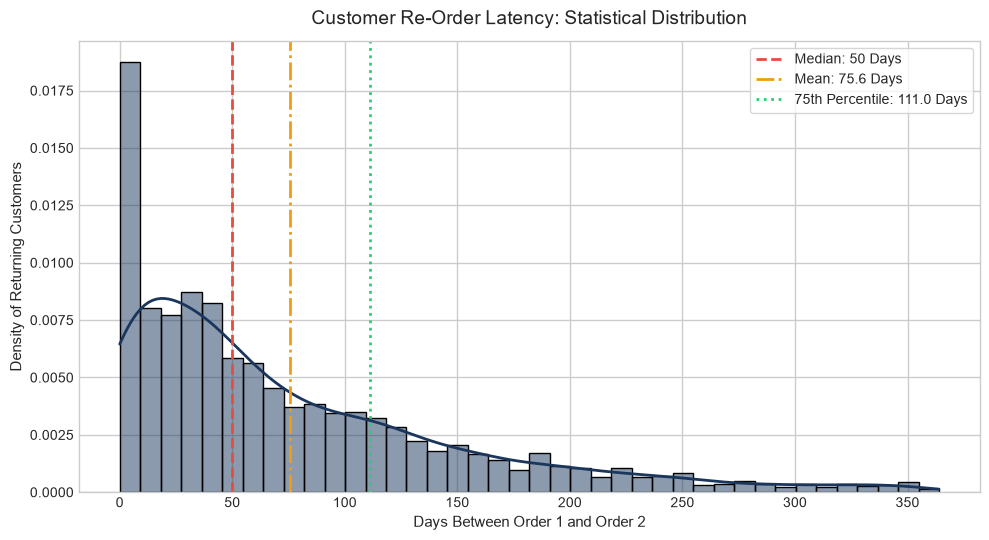

In [52]:
# Clean the series of any missing values if present
latency = Customers_First_To_Second_Order_Duration.dropna()

mean_val = latency.mean()
median_val = latency.median()
q75_val = latency.quantile(0.75)

fig, ax_hist = plt.subplots(figsize = (10, 5.5))

sns.histplot(latency, kde = True, ax = ax_hist, color = "#1B365D", bins = 40, stat = "density")

# Overlaying the exact statistical markers as vertical reference lines
ax_hist.axvline(median_val, color="#E74C3C", linestyle = "--", linewidth = 2, label = f"Median: {median_val:.0f} Days",)
ax_hist.axvline(mean_val, color = "#F39C12", linestyle = "-.", linewidth = 2, label = f"Mean: {mean_val:.1f} Days",)
ax_hist.axvline(q75_val, color = "#2ECC71", linestyle = ":", linewidth = 2, label = f"75th Percentile: {q75_val:.1f} Days",)

ax_hist.set_title("Customer Re-Order Latency: Statistical Distribution", fontsize = 14, pad = 12)
ax_hist.set_xlabel("Days Between Order 1 and Order 2", fontsize = 11)
ax_hist.set_ylabel("Density of Returning Customers", fontsize = 11)
ax_hist.legend(frameon = True, facecolor = "white", loc = "upper right")

plt.tight_layout()
plt.show()

### Key Business Insights: Order Latency & Segment Purchasing Cycles

#### 1. The 50-Day Critical Window (Retail Churn Risk)
* **Observation:** The distribution of time between a customer's first and second order is heavily right-skewed, with a median of 50 days. Once a customer crosses this 50-day threshold without purchasing, their probability of returning drops significantly.
* **Implication:** High Customer Acquisition Cost (CAC) becomes a sunk cost if we lose buyers before their second purchase. Bridging them past Month 1 is critical to stabilizing long-term retention.
* **Actionable Next Step (CRM Escalation Workflow):** 
  * **Day 25:** Send a low-cost engagement trigger (e.g., product recommendations, educational content) as a gentle brand reminder.
  * **Day 45:** For customers who still have not purchased, trigger a high-value discount coupon. This aggressive offer intercepts them right before the 50-day cliff to secure the critical second purchase.

#### 2. The 200+ Day "Long-Tail" Cycle (B2B Wholesale)
* **Observation:** The long tail of the distribution stretches well past the 75th percentile (111 days), with a small but distinct cluster of buyers taking 200+ days to return.
* **Implication:** These long-tail buyers align perfectly with our B2B wholesale VIPs, who operate on annual or seasonal purchasing cycles rather than standard monthly consumer cycles.
* **Actionable Next Step (Seasonal Strategy):**
  * **Q1 Acquisition (Dec–Mar):** Shift focus to acquiring new B2B leads, as historical data proves this is the prime window for wholesale "product sampling." Assign Account Managers to collect feedback and curate custom catalogs.
  * **Q3 Monetization (Pre-September):** Run heavy, targeted bulk-discount marketing strictly for this B2B segment right before their September buying surge to maximize Q4 inventory spend.